In [56]:
import pandas as pd
import numpy as np
import scanpy as sc
import pickle
import anndata as ad
import os
import matplotlib.pyplot as plt
from scipy.stats import entropy
from sklearn.metrics import root_mean_squared_error
from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy import stats

### comparing in-sample and out-of-sample similarity

In [29]:
with open('./Xenium_FFPE_BreastCancer_cellvit_embed.pickle', 'rb') as handle:
    final_embed_norm_recon_df = pickle.load(handle)

In [30]:
### Visium coordinates
visium_coords = pd.read_csv('../Visium/BreastCancer/spatial/tissue_positions.csv')

In [31]:
cell_centroid_0 = final_embed_norm_recon_df['x']
cell_centroid_1 = final_embed_norm_recon_df['y']

In [32]:
visium_coords

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,GTCACTTCCTTCTAGA-1,1,0,0,4550,15271
1,CACGGTCTCCTTACGA-1,1,0,2,4552,15088
2,ATAGCTGCGGATAAGA-1,1,0,4,4553,14905
3,GTCAGTATGTCCGGCG-1,1,0,6,4554,14723
4,ATGTACCAGTTACTCG-1,1,0,8,4556,14540
...,...,...,...,...,...,...
4987,TCCGACCGCAAGTCCT-1,1,77,119,16867,4499
4988,GTCAGTTGGAACCACG-1,1,77,121,16869,4317
4989,GTCGAGACCGTCCGTT-1,1,77,123,16870,4134
4990,TGGCTGGAGTTATTGT-1,1,77,125,16872,3951


In [33]:
radius = 50.
insample_ind = []
for i in range(len(cell_centroid_0)):
    if np.sum((np.abs(visium_coords.loc[:, 'pxl_col_in_fullres'] - cell_centroid_0[i])<= radius) * (np.abs(visium_coords.loc[:, 'pxl_row_in_fullres'] - cell_centroid_1[i])<= radius)):
        insample_ind.append(True)
    else:
        insample_ind.append(False)

In [34]:
np.sum(insample_ind)

36469

In [35]:
len(insample_ind)

169095

In [10]:
def image_features_extract(cell_df, radius, cell_centroid_0=None, cell_centroid_1=None):
    if cell_centroid_0 is None:
        cell_centroid_0 = cell_df['x']
        cell_centroid_1 = cell_df['y']
    
    cell_coords = pd.DataFrame({'Barcode': range(len(cell_centroid_0)), 'pxl_row_in_fullres': cell_centroid_1, 'pxl_col_in_fullres': cell_centroid_0})
    
    cell_coords['lower_x'] = cell_coords['pxl_col_in_fullres'] - radius
    cell_coords['upper_x'] = cell_coords['pxl_col_in_fullres'] + radius
    cell_coords['lower_y'] = cell_coords['pxl_row_in_fullres'] - radius
    cell_coords['upper_y'] = cell_coords['pxl_row_in_fullres'] + radius
    
    cell_coords['lower_x_n1'] = cell_coords['pxl_col_in_fullres'] - radius - 2 * radius
    cell_coords['upper_x_n1'] = cell_coords['pxl_col_in_fullres'] + radius - 2 * radius
    cell_coords['lower_y_n1'] = cell_coords['pxl_row_in_fullres'] - radius + 2 * radius
    cell_coords['upper_y_n1'] = cell_coords['pxl_row_in_fullres'] + radius + 2 * radius

    cell_coords['lower_x_n2'] = cell_coords['pxl_col_in_fullres'] - radius
    cell_coords['upper_x_n2'] = cell_coords['pxl_col_in_fullres'] + radius
    cell_coords['lower_y_n2'] = cell_coords['pxl_row_in_fullres'] - radius + 2 * radius
    cell_coords['upper_y_n2'] = cell_coords['pxl_row_in_fullres'] + radius + 2 * radius

    cell_coords['lower_x_n3'] = cell_coords['pxl_col_in_fullres'] - radius + 2 * radius
    cell_coords['upper_x_n3'] = cell_coords['pxl_col_in_fullres'] + radius + 2 * radius
    cell_coords['lower_y_n3'] = cell_coords['pxl_row_in_fullres'] - radius + 2 * radius
    cell_coords['upper_y_n3'] = cell_coords['pxl_row_in_fullres'] + radius + 2 * radius

    cell_coords['lower_x_n4'] = cell_coords['pxl_col_in_fullres'] - radius - 2 * radius
    cell_coords['upper_x_n4'] = cell_coords['pxl_col_in_fullres'] + radius - 2 * radius
    cell_coords['lower_y_n4'] = cell_coords['pxl_row_in_fullres'] - radius
    cell_coords['upper_y_n4'] = cell_coords['pxl_row_in_fullres'] + radius

    cell_coords['lower_x_n5'] = cell_coords['pxl_col_in_fullres'] - radius + 2 * radius
    cell_coords['upper_x_n5'] = cell_coords['pxl_col_in_fullres'] + radius + 2 * radius
    cell_coords['lower_y_n5'] = cell_coords['pxl_row_in_fullres'] - radius
    cell_coords['upper_y_n5'] = cell_coords['pxl_row_in_fullres'] + radius

    cell_coords['lower_x_n6'] = cell_coords['pxl_col_in_fullres'] - radius - 2 * radius
    cell_coords['upper_x_n6'] = cell_coords['pxl_col_in_fullres'] + radius - 2 * radius
    cell_coords['lower_y_n6'] = cell_coords['pxl_row_in_fullres'] - radius - 2 * radius
    cell_coords['upper_y_n6'] = cell_coords['pxl_row_in_fullres'] + radius - 2 * radius

    cell_coords['lower_x_n7'] = cell_coords['pxl_col_in_fullres'] - radius
    cell_coords['upper_x_n7'] = cell_coords['pxl_col_in_fullres'] + radius
    cell_coords['lower_y_n7'] = cell_coords['pxl_row_in_fullres'] - radius - 2 * radius
    cell_coords['upper_y_n7'] = cell_coords['pxl_row_in_fullres'] + radius - 2 * radius

    cell_coords['lower_x_n8'] = cell_coords['pxl_col_in_fullres'] - radius + 2 * radius
    cell_coords['upper_x_n8'] = cell_coords['pxl_col_in_fullres'] + radius + 2 * radius
    cell_coords['lower_y_n8'] = cell_coords['pxl_row_in_fullres'] - radius - 2 * radius
    cell_coords['upper_y_n8'] = cell_coords['pxl_row_in_fullres'] + radius - 2 * radius
    
    visium_coords = np.array(cell_coords.iloc[:, cell_coords.columns.get_loc('lower_x'):])
    
    x_lower = np.floor(np.min(visium_coords[:, 0])).astype(int)
    x_upper = np.ceil(np.max(visium_coords[:, 1])).astype(int)

    y_lower = np.floor(np.min(visium_coords[:, 2])).astype(int)
    y_upper = np.ceil(np.max(visium_coords[:, 3])).astype(int)

    xI_cells = np.array(cell_df['x'])
    yI_cells = np.array(cell_df['y'])

    cell_df_sub = cell_df.loc[(xI_cells >= x_lower) & (xI_cells <= x_upper) & (yI_cells >= y_lower) & (yI_cells <= y_upper), :]

    xI_cells_sub = np.array(cell_df_sub['x'])
    yI_cells_sub = np.array(cell_df_sub['y'])
    
    cell_df_sub = cell_df_sub.iloc[:, :-2]

    cell_num_mat = np.zeros((visium_coords.shape[0], 9))
    cell_marker_mat = np.zeros((visium_coords.shape[0], 200*9*2))
    
    for j in range(9):
        for i in range(visium_coords.shape[0]):
            cell_df_sub_sub = cell_df_sub.loc[(xI_cells_sub >= visium_coords[i, 0+j*4]) & (xI_cells_sub <= visium_coords[i, 1+j*4]) & (yI_cells_sub >= visium_coords[i, 2+j*4]) & (yI_cells_sub <= visium_coords[i, 3+j*4]), :]
            cell_num_mat[i, j] = cell_df_sub_sub.shape[0]
            
            if cell_df_sub_sub.shape[0] != 0:
                min_markers = np.array(cell_df_sub_sub.min(axis=0))
                max_markers = np.array(cell_df_sub_sub.max(axis=0))
                cell_marker_mat[i, (400*j):(400*j+200)] = min_markers
                cell_marker_mat[i, (400*j+200):(400*(j+1))] = max_markers
    
    return cell_num_mat, cell_marker_mat

In [115]:
cell_num_mat_0, cell_marker_mat_0 = image_features_extract(final_embed_norm_recon_df, 50./8)

In [11]:
def rotate_function(x, y, deg):
    xI_scale = x 
    yI_scale = y
    ## rotate DBiT ROI
    theta_deg = deg
    theta0 = (np.pi/180)*-theta_deg

    #rotation matrix
    #rotates about the origin
    L = np.array([[np.cos(theta0),-np.sin(theta0)],
                  [np.sin(theta0),np.cos(theta0)]])

    source_L = np.matmul(L , np.array([xI_scale, yI_scale]))
    xI_L = source_L[0]
    yI_L = source_L[1]

    #translation matrix
    #effectively makes the rotation about the centroid of I (i.e the means of xI and yI])
    #and also moves the centroid of I to the centroid of J
    T = np.array([ np.mean(xI_scale)- np.cos(theta0)*np.mean(xI_scale) +np.sin(theta0)*np.mean(yI_scale), # - (np.mean(xI_scale)-np.mean(xJ)),
                  np.mean(yI_scale)- np.sin(theta0)*np.mean(xI_scale) -np.cos(theta0)*np.mean(yI_scale)]) # - (np.mean(yI_scale)-np.mean(yJ))])

    xI_L_T = xI_L + T[0] #- 500.
    yI_L_T = yI_L + T[1] #+ 200.
    
    return xI_L_T, yI_L_T

In [13]:
x_0 = np.array(final_embed_norm_recon_df['x'])
y_0 = np.array(final_embed_norm_recon_df['y'])

In [14]:
x_90, y_90 = rotate_function(x_0, y_0, 90)
x_180, y_180 = rotate_function(x_0, y_0, 180)
x_270, y_270 = rotate_function(x_0, y_0, 270)
x_hp, y_hp = -x_0, y_0
x_vp, y_vp = x_0, -y_0

In [15]:
x_hp_90, y_hp_90 = rotate_function(-x_0, y_0, 90)
x_vp_90, y_vp_90 = rotate_function(x_0, -y_0, 90)

In [118]:
cell_num_mat_90, cell_marker_mat_90 = image_features_extract(final_embed_norm_recon_df, 50./8, x_90, y_90)
cell_num_mat_180, cell_marker_mat_180 = image_features_extract(final_embed_norm_recon_df, 50./8, x_180, y_180)
cell_num_mat_270, cell_marker_mat_270 = image_features_extract(final_embed_norm_recon_df, 50./8, x_270, y_270)
cell_num_mat_hp, cell_marker_mat_hp = image_features_extract(final_embed_norm_recon_df, 50./8, x_hp, y_hp)
cell_num_mat_vp, cell_marker_mat_vp = image_features_extract(final_embed_norm_recon_df, 50./8, x_vp, y_vp)

In [16]:
cell_num_mat_hp_90, cell_marker_mat_hp_90 = image_features_extract(final_embed_norm_recon_df, 50./8, x_hp_90, y_hp_90)
cell_num_mat_vp_90, cell_marker_mat_vp_90 = image_features_extract(final_embed_norm_recon_df, 50./8, x_vp_90, y_vp_90)

In [119]:
import pickle
with open('BreastCancer_feature_augmentation.pickle', 'wb') as file:
    pickle.dump((cell_num_mat_0, cell_marker_mat_0, cell_num_mat_90, cell_marker_mat_90, cell_num_mat_180, cell_marker_mat_180, cell_num_mat_270, cell_marker_mat_270, cell_num_mat_hp, cell_marker_mat_hp, cell_num_mat_vp, cell_marker_mat_vp), file)

In [18]:
cell_features_0 = np.hstack((cell_marker_mat_0, cell_num_mat_0))[insample_ind, :]
cell_features_90 = np.hstack((cell_marker_mat_90, cell_num_mat_90))[insample_ind, :]
cell_features_180 = np.hstack((cell_marker_mat_180, cell_num_mat_180))[insample_ind, :]
cell_features_270 = np.hstack((cell_marker_mat_270, cell_num_mat_270))[insample_ind, :]
cell_features_hp = np.hstack((cell_marker_mat_hp, cell_num_mat_hp))[insample_ind, :]
cell_features_vp = np.hstack((cell_marker_mat_vp, cell_num_mat_vp))[insample_ind, :]
cell_features_hp_90 = np.hstack((cell_marker_mat_hp_90, cell_num_mat_hp_90))[insample_ind, :]
cell_features_vp_90 = np.hstack((cell_marker_mat_vp_90, cell_num_mat_vp_90))[insample_ind, :]

In [19]:
## random select 50% cells
rng = np.random.default_rng(seed=42)
sampled_insample_ind = np.random.choice(cell_features_0.shape[0], size = int(cell_features_0.shape[0]*0.5), replace=False)
insample_cell_features = np.vstack((cell_features_0[sampled_insample_ind, :], cell_features_90[sampled_insample_ind, :], cell_features_180[sampled_insample_ind, :], cell_features_270[sampled_insample_ind, :], cell_features_hp[sampled_insample_ind, :], cell_features_vp[sampled_insample_ind, :], cell_features_hp_90[sampled_insample_ind, :], cell_features_vp_90[sampled_insample_ind, :]))

In [20]:
insample_cell_features.shape

(145872, 3609)

In [21]:
## random select 25% cells
rng = np.random.default_rng(seed=42)
sampled_outsample_ind = np.random.choice(np.sum(~np.array(insample_ind)), size = int(np.sum(~np.array(insample_ind))*0.25), replace=False)
outsample_cell_features = np.hstack((cell_marker_mat_0, cell_num_mat_0))[~np.array(insample_ind), :]
outsample_cell_features = outsample_cell_features[sampled_outsample_ind, :]
outsample_cell_features.shape

(33156, 3609)

In [22]:
outsample_cell_x = np.array(final_embed_norm_recon_df['x'])[~np.array(insample_ind)][sampled_outsample_ind]
insample_cell_x = np.array(final_embed_norm_recon_df['x'])[np.array(insample_ind)][sampled_insample_ind]
outsample_cell_y = np.array(final_embed_norm_recon_df['y'])[~np.array(insample_ind)][sampled_outsample_ind]
insample_cell_y = np.array(final_embed_norm_recon_df['y'])[np.array(insample_ind)][sampled_insample_ind]

In [23]:
with open('BreastCancer_feature_in_out_sample.pickle', 'wb') as file:
    pickle.dump((insample_cell_features, outsample_cell_features, insample_cell_x, insample_cell_y, outsample_cell_x, outsample_cell_y), file)

In [ ]:
xenium_grid_data = sc.read_h5ad('./FFPE_BreastCancer_Xneium_grid_aligned.h5ad')
visium_data_sub = sc.read_h5ad('./FFPE_BreastCancer_Xneium_predicted_aligned.h5ad')
xenium_grid_data = xenium_grid_data[:, visium_data_sub.var_names]

insample_visium_xenium_ind = np.intersect1d(np.where(np.array(insample_ind))[0].astype(str), visium_data_sub.obs_names) 
outsample_visium_xenium_ind = np.intersect1d(np.where(~np.array(insample_ind))[0].astype(str), visium_data_sub.obs_names)

xenium_grid_data_outsample = xenium_grid_data[outsample_visium_xenium_ind, :].copy()
visium_data_outsample = visium_data_sub[outsample_visium_xenium_ind, :].copy()

In [ ]:
var_gene = np.var(visium_outsample_array, axis=0)>0

In [ ]:
def xenium_visium_corr(A, B): #A, B are the numpy 2darray for xenium and predicted gene expression
    # 1. Subtract the row means (centering)
    A_centered = A - A.mean(axis=1, keepdims=True)
    B_centered = B - B.mean(axis=1, keepdims=True)

    # 2. Calculate the numerator (dot product of rows)
    numerator = np.sum(A_centered * B_centered, axis=1)

    # 3. Calculate the denominator (product of row norms)
    denominator = np.sqrt(np.sum(A_centered**2, axis=1) * np.sum(B_centered**2, axis=1))

    # 4. Row-wise correlation
    corr = numerator / denominator
    
    return corr

In [ ]:
outsample_corr = xenium_visium_corr(visium_outsample_array[:, var_gene], xenium_outsample_array[:, var_gene])

In [40]:
with open('./BreastCancer_feature_augmentation.pickle', 'rb') as handle:
    cell_num_mat_0, cell_marker_mat_0, cell_num_mat_90, cell_marker_mat_90, cell_num_mat_180, cell_marker_mat_180, cell_num_mat_270, cell_marker_mat_270, cell_num_mat_hp, cell_marker_mat_hp, cell_num_mat_vp, cell_marker_mat_vp = pickle.load(handle)

In [42]:
with open('./BreastCancer_feature_in_out_sample.pickle', 'rb') as handle:
    insample_cell_features, outsample_cell_features, insample_cell_x, insample_cell_y, outsample_cell_x, outsample_cell_y = pickle.load(handle)

In [43]:
import faiss
import numpy as np
from sklearn.decomposition import PCA

# 1. Dimensionality Reduction (PCA)
# Reduce from 3609 to 200 dimensions
pca = PCA(n_components=200, random_state=42)
insample_cell_features_reduced = pca.fit_transform(insample_cell_features).astype('float32')
outsample_cell_features_sub_reduced = pca.transform(outsample_cell_features_sub).astype('float32')

In [44]:
insample_cell_features_reduced_var = np.var(insample_cell_features_reduced, axis=0)

In [45]:
# 1. Build an index (IndexFlatL2 is exact Euclidean distance)
index = faiss.IndexFlatL2(200)
index.add(insample_cell_features_reduced)

distances_sub_all, indices_sub = index.search(outsample_cell_features_sub_reduced, 5)

In [51]:
distances_mean_norm = distances_sub/np.sqrt(np.sum(insample_cell_features_reduced_var))

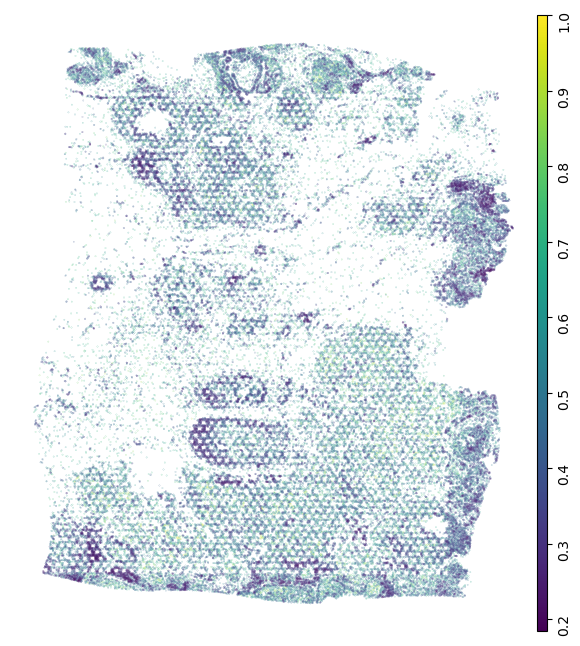

In [75]:
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.left'] = False
plt.rcParams['axes.spines.bottom'] = False
plt.figure(figsize=(8, 8))
sc =plt.scatter(visium_data_outsample.obs['x'], visium_data_outsample.obs['y'], c=np.log1p(1/(np.sqrt(distances_mean_norm)+1.))/np.max(np.log1p(1/(np.sqrt(distances_mean_norm)+1.))), s = 0.01)
# Add the colorbar
#plt.suptitle('Scatterplot of out-of-sample cells colored by credibility score', ha='center')
cbar = plt.colorbar(sc, format='%.1f', aspect=60, pad=0)
cbar.ax.tick_params(axis='y', labelrotation=90)
#cbar.set_label('Credibility = log1p(1/avg_dist)', rotation=270, labelpad=20)
plt.axis('off')
plt.show()

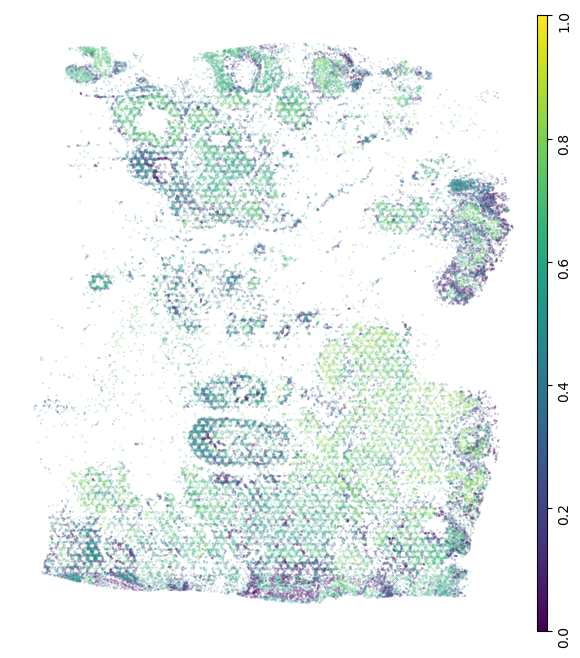

In [95]:
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.left'] = False
plt.rcParams['axes.spines.bottom'] = False
plt.figure(figsize=(8, 8))
sc =plt.scatter(visium_data_outsample.obs['x'][~np.isnan(outsample_corr)], visium_data_outsample.obs['y'][~np.isnan(outsample_corr)], c=outsample_corr[~np.isnan(outsample_corr)], s = 0.01, vmin=0, vmax=1.0)
# Add the colorbar
#plt.title('Scatterplot of out-of-sample cells colored by corrlation with underlying Xenium expression')
cbar = plt.colorbar(sc, format='%.1f', aspect=60, pad=0)
cbar.ax.tick_params(axis='y', labelrotation=90)
plt.axis('off')
plt.show()

In [103]:
import os
import argparse
import sys
from matplotlib import pyplot as plt
import json 
import scanpy as sc 
from PIL import Image
import cv2
from shapely import geometry
from shapely.geometry import Polygon
import rasterio.features
from scipy.sparse import issparse

# Get the absolute path to the directory containing the script to be imported
script_dir = os.path.abspath("/gpfs/ycga/work/fan/yl2499/istar/iStar")
# Add the directory to sys.path
sys.path.append(script_dir)
from iStar.utils import load_image
from iStar.plot_imputed import plot_super

def rescale(value, scalefactor):
    return int(np.round(value*scalefactor))

def resize_array(arr, target_shape, interpolation=cv2.INTER_LINEAR):
    import cv2
    return cv2.resize(arr, target_shape, interpolation=interpolation) 

def get_downscaled_im(gene_array, scalefactor, locs, image_size):
    xmin, ymin = 1, 1
    xmax, ymax = image_size

    grid_sizes = (rescale(ymax, scalefactor), rescale(xmax, scalefactor))
    grid_values = np.zeros(grid_sizes)

    # Populate the grid with values from the spatial data
    x = locs[:, 0]
    y = locs[:, 1]

    col_index = np.digitize(x, np.linspace(xmin, xmax, grid_sizes[1])).astype(int)
    row_index = np.digitize(y, np.linspace(ymin, ymax, grid_sizes[0])).astype(int)

    # Assign the value to the corresponding grid cell
    grid_values[row_index - 1, col_index - 1] += gene_array#[:, 0]

    grid_values[grid_values < 0] = 0
    return grid_values

In [526]:
image_size = (np.max(visium_data_outsample.obs['x']).astype(int), 
              np.max(visium_data_outsample.obs['y']).astype(int))

In [527]:
locs1 = np.array([visium_data_outsample.obs['x'][~np.isnan(outsample_corr)], visium_data_outsample.obs['y'][~np.isnan(outsample_corr)]]).T
locs2 = np.array([visium_data_outsample.obs['x'], visium_data_outsample.obs['y']]).T

In [529]:
locs2.shape

(94118, 2)

In [591]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from pytorch_msssim import ms_ssim

def get_plot_array(x, y, c, vmax=None):
    # Create figure without axes/margins
    fig, ax = plt.subplots(figsize=(5.4, 7.5), dpi=300)
    ax.scatter(x, y, c=c, s=0.01, vmax=vmax)
    ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    
    # Render to a NumPy array (RGB)
    fig.canvas.draw()
    rgba_buffer = np.array(fig.canvas.renderer.buffer_rgba())
    plt.close(fig)
    
    # Convert RGBA to RGB and normalize to [0, 1]
    rgb_array = rgba_buffer[:, :, :3] / 255.0
    return rgb_array

# Sample Data
x1, y1 = visium_data_outsample.obs['x'][~np.isnan(outsample_corr)], visium_data_outsample.obs['y'][~np.isnan(outsample_corr)]
x2, y2 = visium_data_outsample.obs['x'], visium_data_outsample.obs['y']
# Get arrays
arr1 = get_plot_array(x1, y1, outsample_corr[~np.isnan(outsample_corr)])
arr2 = get_plot_array(x2, y2, np.log1p(1/(np.sqrt(distances_mean_norm)+1.))/np.max(np.log1p(1/(np.sqrt(distances_mean_norm)+1.))), vmax=1.0)
print(arr1.shape)

# Convert to PyTorch Tensors (Batch, Channel, Height, Width)
img1 = torch.from_numpy(arr1).permute(2, 0, 1).unsqueeze(0).float()
img2 = torch.from_numpy(arr2).permute(2, 0, 1).unsqueeze(0).float()

(2250, 1620, 3)


In [592]:
# Calculate MS-SSIM
ms_ssim(img1, img2, data_range=1.0, win_size=11)

In [594]:
credibility_array = 1/np.sqrt(distances_gmean)
permutation_score = []
for i in range(1000):
    if i %50==0:
        print(i)
    shuffled_credibility = np.random.permutation(credibility_array)
    shuffled_arr2 = get_plot_array(x2, y2, shuffled_credibility, vmax=0.05)
    shuffled_img2 = torch.from_numpy(shuffled_arr2).permute(2, 0, 1).unsqueeze(0).float()
    permutation_score.append(ms_ssim(img1, shuffled_img2, data_range=1.0))

0
50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950


In [597]:
np.sum(np.array(permutation_score) >= 0.7290)/1000

0.0